# Автоматическое определение вида грибов на основе искусственной нейронной сети

Notebook построен как единый воспроизводимый сценарий: подготовка данных, стратифицированное разбиение, обучение EfficientNetB0, расчёт метрик, экспорт результатов и формирование `glarus_report.xlsx`.


In [1]:
# 1. Подготовка окружения
user_lib <- "C:/Users/geezix/AppData/Local/R/win-library/4.6"
dir.create(user_lib, recursive = TRUE, showWarnings = FALSE)
.libPaths(c(user_lib, .libPaths()))

required_packages <- c("reticulate", "dplyr", "tidyr", "readr", "ggplot2", "openxlsx")

install_missing <- function(packages) {
  missing <- packages[!vapply(packages, requireNamespace, logical(1), quietly = TRUE)]
  if (length(missing) > 0) {
    install.packages(missing, lib = user_lib, repos = "https://cloud.r-project.org")
  }
}

install_missing(required_packages)

library(reticulate)
library(dplyr)
library(tidyr)
library(readr)
library(ggplot2)
library(openxlsx)

Sys.setenv(RETICULATE_PYTHON = "C:/Users/geezix/scoop/apps/python312/3.12.10/python.exe")

py_config()



Присоединяю пакет: 'dplyr'


Следующие объекты скрыты от 'package:stats':

    filter, lag


Следующие объекты скрыты от 'package:base':

    intersect, setdiff, setequal, union




python:         C:/Users/geezix/scoop/apps/python312/3.12.10/python.exe
libpython:      C:/Users/geezix/scoop/apps/python312/3.12.10/python312.dll
pythonhome:     C:/Users/geezix/scoop/apps/python312/3.12.10
version:        3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Architecture:   64bit
numpy:          C:/Users/geezix/AppData/Roaming/Python/Python312/site-packages/numpy
numpy_version:  2.4.6

NOTE: Python version was forced by RETICULATE_PYTHON

In [2]:
# 2. Параметры эксперимента
set.seed(42)

DATA_DIR <- "Mushrooms"
RESULTS_DIR <- "results_mushroom_efficientnet"
PREDICT_DIR <- "predict_images"

IMG_HEIGHT <- 224L
IMG_WIDTH <- 224L
BATCH_SIZE <- 48L
EPOCHS_HEAD <- 35L
EPOCHS_FINE <- 25L
SEED <- 42L
ALLOWED_EXT <- c("jpg", "jpeg", "png", "bmp", "webp")

dir.create(RESULTS_DIR, recursive = TRUE, showWarnings = FALSE)
dir.create(PREDICT_DIR, recursive = TRUE, showWarnings = FALSE)


In [3]:
# 3. Индексация изображений и первичный контроль данных
if (!dir.exists(DATA_DIR)) {
  stop("Каталог Mushrooms не найден. Поместите папку с изображениями рядом с notebook.")
}

class_names <- sort(list.dirs(DATA_DIR, full.names = FALSE, recursive = FALSE))
if (length(class_names) < 2) {
  stop("В каталоге Mushrooms должно быть не менее двух папок-классов.")
}

collect_images <- function(data_dir, class_names, allowed_ext) {
  rows <- lapply(class_names, function(cls) {
    cls_dir <- file.path(data_dir, cls)
    files <- list.files(cls_dir, full.names = TRUE, recursive = TRUE)
    ext <- tolower(tools::file_ext(files))
    files <- files[ext %in% allowed_ext]
    if (length(files) == 0) return(NULL)
    data.frame(filepath = normalizePath(files, winslash = "/", mustWork = TRUE), class = cls)
  })
  bind_rows(rows)
}

image_index <- collect_images(DATA_DIR, class_names, ALLOWED_EXT)
if (nrow(image_index) == 0) stop("Изображения допустимых форматов не найдены.")

image_counts <- image_index %>%
  count(class, name = "n") %>%
  mutate(share = n / sum(n)) %>%
  arrange(class)

write_csv(image_index, file.path(RESULTS_DIR, "image_index.csv"))
write_csv(image_counts, file.path(RESULTS_DIR, "image_counts_by_class.csv"))
write_csv(data.frame(class = class_names), file.path(RESULTS_DIR, "class_names.csv"))

image_counts


class,n,share
<chr>,<int>,<dbl>
Agaricus,353,0.05258454
Amanita,750,0.11172352
Boletus,1073,0.15983912
Cortinarius,836,0.12453449
Entoloma,364,0.05422315
Hygrocybe,316,0.04707284
Lactarius,1563,0.23283182
Russula,1147,0.17086251
Suillus,311,0.04632802


In [4]:
# 4. Стратифицированное разбиение на train / validation / test
stratified_split <- function(df, train_frac = 0.70, val_frac = 0.15, seed = 42) {
  set.seed(seed)
  df %>%
    group_by(class) %>%
    group_modify(~{
      x <- .x[sample(nrow(.x)), , drop = FALSE]
      n <- nrow(x)
      n_train <- floor(train_frac * n)
      n_val <- floor(val_frac * n)
      x$split <- "test"
      x$split[seq_len(n_train)] <- "train"
      if (n_val > 0) {
        x$split[(n_train + 1):(n_train + n_val)] <- "validation"
      }
      x
    }) %>%
    ungroup()
}

dataset_split <- stratified_split(image_index, seed = SEED)
split_counts <- dataset_split %>% count(class, split, name = "n") %>% arrange(class, split)

write_csv(dataset_split, file.path(RESULTS_DIR, "dataset_split.csv"))
write_csv(split_counts, file.path(RESULTS_DIR, "split_counts_by_class.csv"))

split_counts


class,split,n
<chr>,<chr>,<int>
Agaricus,test,54
Agaricus,train,247
Agaricus,validation,52
Amanita,test,113
Amanita,train,525
Amanita,validation,112
Boletus,test,162
Boletus,train,751
Boletus,validation,160


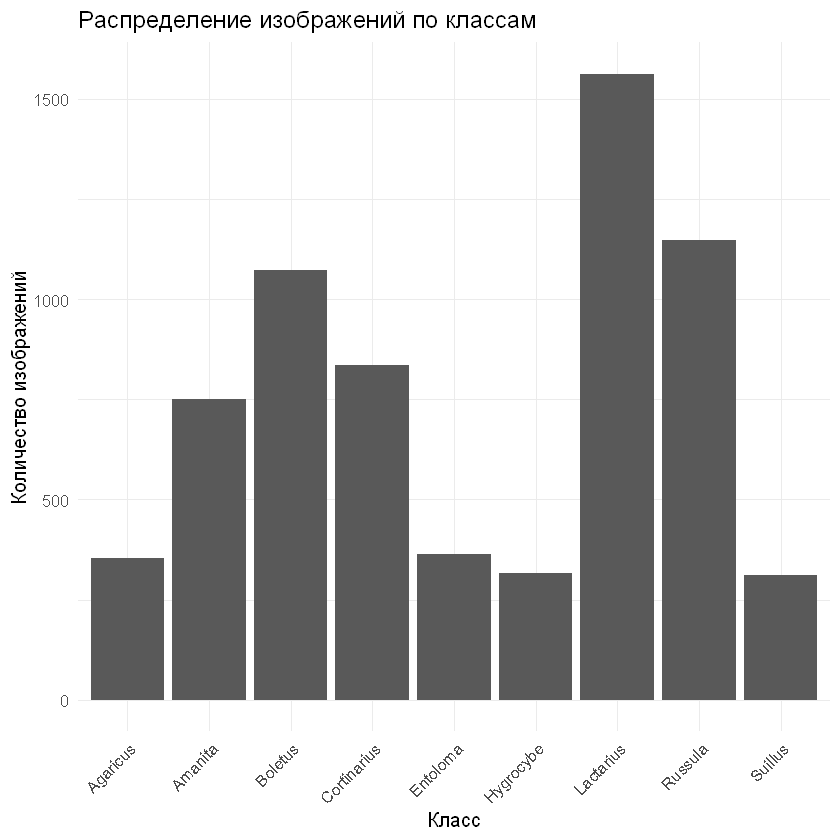

In [5]:
# 5. График распределения классов
p_counts <- ggplot(image_counts, aes(x = class, y = n)) +
  geom_col() +
  labs(title = "Распределение изображений по классам", x = "Класс", y = "Количество изображений") +
  theme_minimal(base_size = 12) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

ggsave(file.path(RESULTS_DIR, "class_distribution.png"), p_counts, width = 8, height = 4.5, dpi = 160)
p_counts


In [ ]:
# 6. Python-блок обучения и оценки модели
python_training_code <- r"---(

from __future__ import annotations

import random
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers


def set_global_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


def prepare_dataframe(split_csv: str, class_names: List[str]) -> pd.DataFrame:
    df = pd.read_csv(split_csv)
    required = {"filepath", "class", "split"}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"В dataset_split.csv отсутствуют поля: {sorted(missing)}")
    df = df[df["class"].isin(class_names)].copy()
    if df.empty:
        raise ValueError("После фильтрации классов таблица данных пуста.")
    return df


def compute_class_weights(train_df: pd.DataFrame, class_names: List[str]) -> Dict[int, float]:
    counts = train_df["class"].value_counts().to_dict()
    n_total = len(train_df)
    n_classes = len(class_names)
    weights = {}
    for idx, cls in enumerate(class_names):
        n_cls = counts.get(cls, 0)
        weights[idx] = 1.0 if n_cls == 0 else n_total / (n_classes * n_cls)
    return weights


def make_dataset(
    df: pd.DataFrame,
    class_to_id: Dict[str, int],
    img_size: Tuple[int, int],
    batch_size: int,
    training: bool,
) -> tf.data.Dataset:
    paths = df["filepath"].astype(str).to_numpy()
    labels = df["class"].map(class_to_id).astype("int32").to_numpy()

    def load_image(path, label):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
        image = tf.image.resize(image, img_size, method="bilinear")
        image.set_shape((img_size[0], img_size[1], 3))
        label = tf.one_hot(label, depth=len(class_to_id))
        return image, label

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(df), seed=42, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


def build_model(num_classes: int, img_size: Tuple[int, int], dropout: float = 0.35) -> keras.Model:
    inputs = keras.Input(shape=(img_size[0], img_size[1], 3), name="image")
    augmentation = keras.Sequential(
        [
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            layers.RandomZoom(0.08),
            layers.RandomContrast(0.08),
        ],
        name="augmentation",
    )
    x = augmentation(inputs)
    x = keras.applications.efficientnet.preprocess_input(x)

    base_model = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(img_size[0], img_size[1], 3),
        pooling="avg",
    )
    base_model.trainable = False

    x = base_model(x, training=False)
    x = layers.BatchNormalization(name="head_bn_1")(x)
    x = layers.Dropout(dropout, name="head_dropout_1")(x)
    x = layers.Dense(512, activation="relu", kernel_regularizer=regularizers.l2(1e-4), name="head_dense_512")(x)
    x = layers.BatchNormalization(name="head_bn_2")(x)
    x = layers.Dropout(dropout, name="head_dropout_2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="class_probabilities")(x)
    model = keras.Model(inputs=inputs, outputs=outputs, name="mushroom_efficientnet_b0")
    model.base_model = base_model
    return model


def compile_model(model: keras.Model, learning_rate: float) -> None:
    try:
        optimizer = keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=1e-5)
    except Exception:
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss="categorical_crossentropy", metrics=["accuracy"])


def evaluate_predictions(y_true: np.ndarray, y_pred: np.ndarray, class_names: List[str]):
    n_classes = len(class_names)
    cm = tf.math.confusion_matrix(y_true, y_pred, num_classes=n_classes).numpy()
    rows = []
    for idx, cls in enumerate(class_names):
        tp = cm[idx, idx]
        fp = cm[:, idx].sum() - tp
        fn = cm[idx, :].sum() - tp
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        rows.append({"class": cls, "precision": precision, "recall": recall, "f1": f1, "support": int(cm[idx, :].sum())})
    per_class = pd.DataFrame(rows)
    summary = {
        "Accuracy": float((y_true == y_pred).mean()),
        "Macro Precision": float(per_class["precision"].mean()),
        "Macro Recall": float(per_class["recall"].mean()),
        "Macro F1": float(per_class["f1"].mean()),
    }
    return summary, per_class, cm


def save_glarus_report(results_dir: Path) -> None:
    xlsx_path = results_dir / "glarus_report.xlsx"
    with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
        for filename, sheet in [
            ("image_counts_by_class.csv", "class_counts"),
            ("split_counts_by_class.csv", "split_counts"),
            ("metrics_summary.csv", "summary_metrics"),
            ("per_class_metrics.csv", "class_metrics"),
            ("batch_predictions.csv", "predictions"),
        ]:
            path = results_dir / filename
            if path.exists():
                pd.read_csv(path).to_excel(writer, sheet_name=sheet, index=False)


def run_experiment(
    split_csv: str,
    results_dir: str,
    class_names: List[str],
    img_height: int,
    img_width: int,
    batch_size: int,
    epochs_head: int,
    epochs_fine: int,
    seed: int = 42,
):
    set_global_seed(seed)
    results_dir = Path(results_dir)
    results_dir.mkdir(parents=True, exist_ok=True)
    class_names = list(class_names)
    class_to_id = {name: idx for idx, name in enumerate(class_names)}
    img_size = (int(img_height), int(img_width))

    df = prepare_dataframe(split_csv, class_names)
    train_df = df[df["split"] == "train"].copy()
    val_df = df[df["split"] == "validation"].copy()
    test_df = df[df["split"] == "test"].copy()
    if min(len(train_df), len(val_df), len(test_df)) == 0:
        raise ValueError("Одна из выборок train/validation/test пуста.")

    train_ds = make_dataset(train_df, class_to_id, img_size, batch_size, training=True)
    val_ds = make_dataset(val_df, class_to_id, img_size, batch_size, training=False)
    test_ds = make_dataset(test_df, class_to_id, img_size, batch_size, training=False)
    class_weights = compute_class_weights(train_df, class_names)

    model = build_model(num_classes=len(class_names), img_size=img_size)
    compile_model(model, learning_rate=2e-4)
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(results_dir / "mushroom_efficientnet_model.keras"), monitor="val_accuracy", save_best_only=True, mode="max"),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6),
    ]
    history_head = model.fit(train_ds, validation_data=val_ds, epochs=int(epochs_head), callbacks=callbacks, class_weight=class_weights, verbose=1)

    base_model = model.base_model
    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False
    compile_model(model, learning_rate=2e-5)
    history_fine = model.fit(train_ds, validation_data=val_ds, epochs=int(epochs_fine), callbacks=callbacks, class_weight=class_weights, verbose=1)

    if (results_dir / "mushroom_efficientnet_model.keras").exists():
        model = keras.models.load_model(results_dir / "mushroom_efficientnet_model.keras")
    else:
        model.save(results_dir / "mushroom_efficientnet_model.keras")

    histories = []
    for stage, hist in [("head", history_head), ("fine_tuning", history_fine)]:
        h = pd.DataFrame(hist.history)
        h["epoch"] = np.arange(1, len(h) + 1)
        h["stage"] = stage
        histories.append(h)
    pd.concat(histories, ignore_index=True).to_csv(results_dir / "training_history.csv", index=False)

    y_true, y_prob = [], []
    for images, labels in test_ds:
        probs = model.predict(images, verbose=0)
        y_prob.append(probs)
        y_true.append(np.argmax(labels.numpy(), axis=1))
    y_prob = np.vstack(y_prob)
    y_true = np.concatenate(y_true)
    y_pred = np.argmax(y_prob, axis=1)

    summary, per_class, cm = evaluate_predictions(y_true, y_pred, class_names)
    pd.DataFrame([summary]).to_csv(results_dir / "metrics_summary.csv", index=False)
    per_class.to_csv(results_dir / "per_class_metrics.csv", index=False)
    cm_wide = pd.DataFrame(cm, index=class_names, columns=class_names)
    cm_wide.index.name = "true_class"
    cm_wide.to_csv(results_dir / "confusion_matrix_wide.csv")
    cm_long = cm_wide.reset_index().melt(id_vars="true_class", var_name="predicted_class", value_name="count")
    cm_long.to_csv(results_dir / "confusion_matrix.csv", index=False)
    save_glarus_report(results_dir)
    return summary


def predict_folder(model_path: str, predict_dir: str, results_dir: str, class_names: List[str], img_height: int, img_width: int, min_confidence: float = 0.65, min_margin: float = 0.15):
    model = keras.models.load_model(model_path)
    predict_dir = Path(predict_dir)
    results_dir = Path(results_dir)
    class_names = list(class_names)
    allowed = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    rows = []
    for path in sorted(predict_dir.iterdir()):
        if path.suffix.lower() not in allowed:
            continue
        image_bytes = tf.io.read_file(str(path))
        image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
        image = tf.image.resize(image, (img_height, img_width))
        image = tf.expand_dims(image, axis=0)
        probs = model.predict(image, verbose=0)[0]
        order = np.argsort(probs)[::-1]
        top1, top2 = int(order[0]), int(order[1])
        confidence = float(probs[top1])
        margin = float(probs[top1] - probs[top2])
        rows.append({
            "file_name": path.name,
            "predicted_class": class_names[top1],
            "confidence": confidence,
            "second_class": class_names[top2],
            "second_probability": float(probs[top2]),
            "margin": margin,
            "is_confident": bool(confidence >= min_confidence and margin >= min_margin),
        })
    result = pd.DataFrame(rows)
    result.to_csv(results_dir / "batch_predictions.csv", index=False)
    save_glarus_report(results_dir)
    return result

)---"

py_run_string(python_training_code)


In [ ]:
# 7. Запуск обучения
Sys.setenv(TF_ENABLE_ONEDNN_OPTS = "0")
Sys.setenv(TF_CPP_MIN_LOG_LEVEL = "1")

library(reticulate)
library(tensorflow)
library(keras)

gpus <- tf$config$list_physical_devices("GPU")
print(gpus)

if (length(gpus) > 0) {
  for (gpu in gpus) {
    tf$config$experimental$set_memory_growth(gpu, TRUE)
  }
}


training_result <- py$run_experiment(
  split_csv = normalizePath(file.path(RESULTS_DIR, "dataset_split.csv"), winslash = "/", mustWork = TRUE),
  results_dir = normalizePath(RESULTS_DIR, winslash = "/", mustWork = TRUE),
  class_names = as.list(class_names),
  img_height = as.integer(IMG_HEIGHT),
  img_width = as.integer(IMG_WIDTH),
  batch_size = as.integer(BATCH_SIZE),
  epochs_head = as.integer(EPOCHS_HEAD),
  epochs_fine = as.integer(EPOCHS_FINE),
  seed = as.integer(SEED)
)

training_result


The keras package is deprecated. Please use the keras3 package instead.
Alternatively, to continue using legacy keras, call `py_require_legacy_keras()`.



In [ ]:
# 8. Чтение результатов и построение графиков
metrics_summary <- read_csv(file.path(RESULTS_DIR, "metrics_summary.csv"), show_col_types = FALSE)
per_class_metrics <- read_csv(file.path(RESULTS_DIR, "per_class_metrics.csv"), show_col_types = FALSE)
training_history <- read_csv(file.path(RESULTS_DIR, "training_history.csv"), show_col_types = FALSE)

metrics_summary
per_class_metrics

if (all(c("accuracy", "val_accuracy", "epoch", "stage") %in% names(training_history))) {
  p_acc <- ggplot(training_history, aes(x = epoch)) +
    geom_line(aes(y = accuracy, linetype = "train")) +
    geom_line(aes(y = val_accuracy, linetype = "validation")) +
    facet_wrap(~stage, scales = "free_x") +
    labs(title = "Динамика accuracy", x = "Эпоха", y = "Accuracy", linetype = "Выборка") +
    theme_minimal(base_size = 12)
  ggsave(file.path(RESULTS_DIR, "accuracy_history.png"), p_acc, width = 8, height = 4.5, dpi = 160)
  print(p_acc)
}

p_f1 <- ggplot(per_class_metrics, aes(x = reorder(class, f1), y = f1)) +
  geom_col() +
  coord_flip() +
  labs(title = "F1-score по классам", x = "Класс", y = "F1-score") +
  theme_minimal(base_size = 12)

ggsave(file.path(RESULTS_DIR, "f1_by_class.png"), p_f1, width = 7, height = 4.5, dpi = 160)
p_f1


In [ ]:
# 9. Проверка пользовательских изображений
model_path <- normalizePath(file.path(RESULTS_DIR, "mushroom_efficientnet_model.keras"), winslash = "/", mustWork = FALSE)

if (file.exists(model_path)) {
  predictions <- py$predict_folder(
    model_path = model_path,
    predict_dir = normalizePath(PREDICT_DIR, winslash = "/", mustWork = TRUE),
    results_dir = normalizePath(RESULTS_DIR, winslash = "/", mustWork = TRUE),
    class_names = as.list(class_names),
    img_height = as.integer(IMG_HEIGHT),
    img_width = as.integer(IMG_WIDTH),
    min_confidence = 0.65,
    min_margin = 0.15
  )
  predictions
} else {
  message("Модель пока не обучена. Сначала выполните блок обучения.")
}
